# Week 5 Task: Deep Learning Application in Data Science
Binary classification: predict income >$50K vs <=$50K, using PyTorch
Dataset: UCI Adult / Census Income (same features as Week 4, for a fair comparison)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os, time

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, roc_curve, confusion_matrix)

sns.set_style("whitegrid")
os.makedirs("outputs", exist_ok=True)
np.random.seed(42)
torch.manual_seed(42)

df = pd.read_csv("adult_dataset_cleaned.csv")
df.shape

(48790, 15)

## 1. Feature engineering (identical to Week 4)

In [2]:
df["income_binary"] = (df["income"] == ">50K").astype(int)
drop_cols = ["fnlwgt", "income", "education"]
work_df = df.drop(columns=drop_cols)

work_df["capital_net"] = work_df["capital-gain"] - work_df["capital-loss"]
work_df["has_capital_gain"] = (work_df["capital-gain"] > 0).astype(int)
work_df["has_capital_loss"] = (work_df["capital-loss"] > 0).astype(int)
work_df["is_overtime"] = (work_df["hours-per-week"] > 40).astype(int)
work_df["is_us_native"] = (work_df["native-country"] == "United-States").astype(int)
work_df = work_df.drop(columns=["native-country"])

categorical_cols = ["workclass", "marital-status", "occupation", "relationship", "race", "sex"]
encoded = pd.get_dummies(work_df, columns=categorical_cols, drop_first=True, dtype=int)

X = encoded.drop(columns=["income_binary"]).values.astype(np.float32)
y = encoded["income_binary"].values.astype(np.float32)
X.shape

(48790, 48)

## 2. Train / validation / test split (60/20/20)

In [3]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25, random_state=42, stratify=y_train_full
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

def to_tensor(arr): return torch.tensor(arr, dtype=torch.float32)

train_ds = TensorDataset(to_tensor(X_train_s), to_tensor(y_train))
val_ds = TensorDataset(to_tensor(X_val_s), to_tensor(y_val))
test_ds = TensorDataset(to_tensor(X_test_s), to_tensor(y_test))

BATCH_SIZE = 256
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)
print(X_train.shape, X_val.shape, X_test.shape)

(29274, 48) (9758, 48) (9758, 48)


## 3. Model architecture

In [4]:
class IncomeMLP(nn.Module):
    def __init__(self, n_features, hidden1=64, hidden2=32, hidden3=16, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, hidden1), nn.BatchNorm1d(hidden1), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden1, hidden2), nn.BatchNorm1d(hidden2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden2, hidden3), nn.ReLU(),
            nn.Linear(hidden3, 1),
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)

model = IncomeMLP(n_features=X.shape[1])
print(model)
print("Total params:", sum(p.numel() for p in model.parameters()))

IncomeMLP(
  (net): Sequential(
    (0): Linear(in_features=48, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=32, out_features=16, bias=True)
    (9): ReLU()
    (10): Linear(in_features=16, out_features=1, bias=True)
  )
)
Total params: 5953


## 4. Loss, optimizer, and class-imbalance handling

In [5]:
n_pos = y_train.sum()
n_neg = len(y_train) - n_pos
pos_weight_value = n_neg / n_pos
print("pos_weight:", pos_weight_value)

criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pos_weight_value))
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)

pos_weight: 3.17663


## 5. Training loop with early stopping

In [6]:
MAX_EPOCHS = 60
PATIENCE = 8
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_loss = float("inf")
best_state = None
epochs_no_improve = 0

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    train_losses, train_correct, train_total = [], 0, 0
    for xb, yb in train_loader:
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        train_losses.append(loss.item() * len(xb))
        preds = (torch.sigmoid(logits) > 0.5).float()
        train_correct += (preds == yb).sum().item()
        train_total += len(xb)

    model.eval()
    val_losses, val_correct, val_total = [], 0, 0
    with torch.no_grad():
        for xb, yb in val_loader:
            logits = model(xb)
            loss = criterion(logits, yb)
            val_losses.append(loss.item() * len(xb))
            preds = (torch.sigmoid(logits) > 0.5).float()
            val_correct += (preds == yb).sum().item()
            val_total += len(xb)

    tl, vl = sum(train_losses)/train_total, sum(val_losses)/val_total
    ta, va = train_correct/train_total, val_correct/val_total
    history["train_loss"].append(tl); history["val_loss"].append(vl)
    history["train_acc"].append(ta); history["val_acc"].append(va)
    scheduler.step(vl)

    if vl < best_val_loss - 1e-4:
        best_val_loss = vl
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
    if epochs_no_improve >= PATIENCE:
        print(f"Early stopping at epoch {epoch}")
        break

model.load_state_dict(best_state)
print("Best val loss:", best_val_loss)

Early stopping at epoch 25
Best val loss: 0.5649628275900401


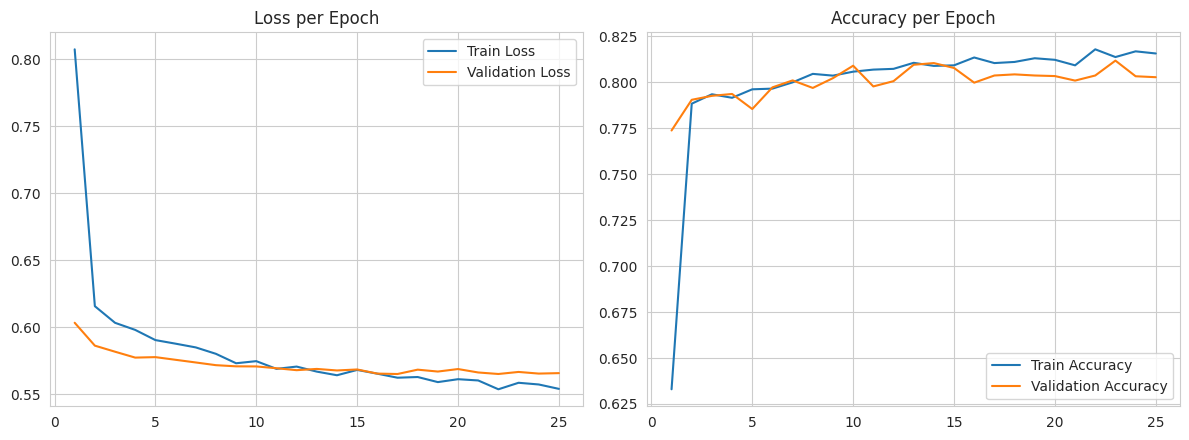

In [7]:
epochs_range = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12,4.5))
axes[0].plot(epochs_range, history["train_loss"], label="Train Loss")
axes[0].plot(epochs_range, history["val_loss"], label="Validation Loss")
axes[0].set_title("Loss per Epoch"); axes[0].legend()
axes[1].plot(epochs_range, history["train_acc"], label="Train Accuracy")
axes[1].plot(epochs_range, history["val_acc"], label="Validation Accuracy")
axes[1].set_title("Accuracy per Epoch"); axes[1].legend()
plt.tight_layout(); plt.savefig("outputs/01_training_curves.png", dpi=150); plt.show()

## 6. Test set evaluation

In [8]:
model.eval()
all_logits, all_labels = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        all_logits.append(model(xb)); all_labels.append(yb)
all_logits = torch.cat(all_logits)
all_labels = torch.cat(all_labels).numpy()
all_probs = torch.sigmoid(all_logits).numpy()
all_preds = (all_probs > 0.5).astype(int)

mlp_metrics = {
    "accuracy": accuracy_score(all_labels, all_preds),
    "precision": precision_score(all_labels, all_preds),
    "recall": recall_score(all_labels, all_preds),
    "f1": f1_score(all_labels, all_preds),
    "roc_auc": roc_auc_score(all_labels, all_probs),
}
mlp_metrics

{'accuracy': 0.8055954088952654,
 'precision': 0.5601534667032063,
 'recall': 0.875,
 'f1': 0.6830409356725147,
 'roc_auc': 0.9159722299125517}

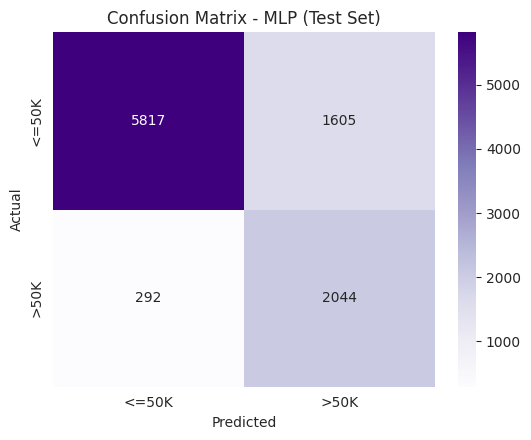

In [9]:
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(5.5,4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Purples", xticklabels=["<=50K",">50K"], yticklabels=["<=50K",">50K"])
plt.title("Confusion Matrix - MLP (Test Set)"); plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout(); plt.savefig("outputs/02_confusion_matrix.png", dpi=150); plt.show()

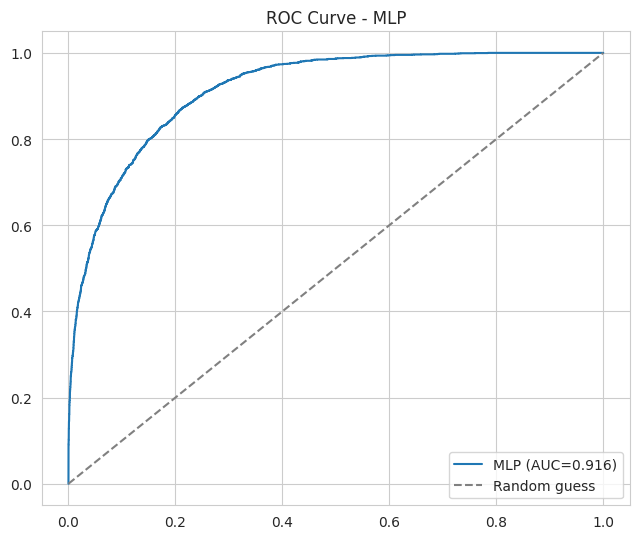

In [10]:
fpr, tpr, _ = roc_curve(all_labels, all_probs)
plt.figure(figsize=(6.5,5.5))
plt.plot(fpr, tpr, label=f"MLP (AUC={mlp_metrics['roc_auc']:.3f})")
plt.plot([0,1],[0,1], linestyle="--", color="grey", label="Random guess")
plt.title("ROC Curve - MLP"); plt.legend()
plt.tight_layout(); plt.savefig("outputs/03_roc_curve.png", dpi=150); plt.show()

## 7. Comparison with Week 4 classical models

In [11]:
week4_metrics = {
    "Logistic Regression": {"accuracy": 0.8123, "precision": 0.5727, "recall": 0.8502, "f1": 0.6844, "roc_auc": 0.9125},
    "Random Forest (tuned)": {"accuracy": 0.8241, "precision": 0.5909, "recall": 0.8626, "f1": 0.7014, "roc_auc": 0.9245},
}
comparison = pd.DataFrame({
    "Logistic Regression": week4_metrics["Logistic Regression"],
    "Random Forest (tuned)": week4_metrics["Random Forest (tuned)"],
    "MLP (this week)": mlp_metrics,
}).T
comparison

,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.812300,0.572700,0.8502,0.684400,0.912500
Random Forest (tuned),0.824100,0.590900,0.8626,0.701400,0.924500
MLP (this week),0.805595,0.560153,0.8750,0.683041,0.915972


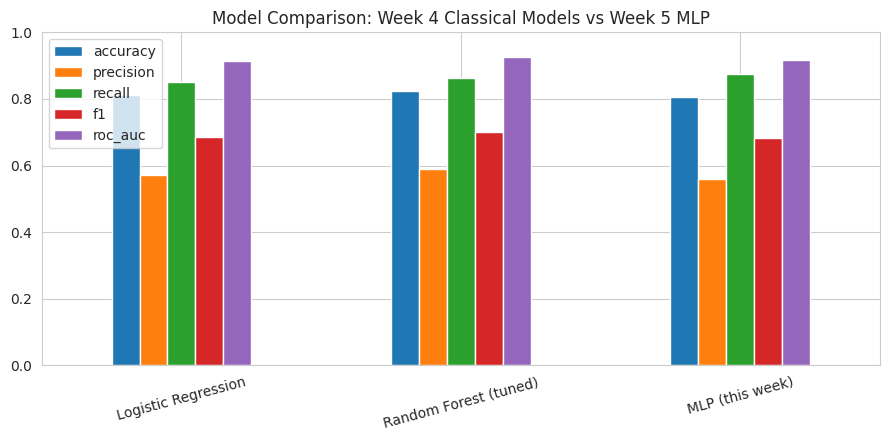

In [12]:
comparison.plot(kind="bar", figsize=(9,4.5))
plt.title("Model Comparison: Week 4 Classical Models vs Week 5 MLP")
plt.ylim(0,1); plt.xticks(rotation=15)
plt.tight_layout(); plt.savefig("outputs/04_model_comparison.png", dpi=150); plt.show()

## 8. Ablation study: overfitting with vs without regularization

In [13]:
class SimpleMLP(nn.Module):
    def __init__(self, n_features, hidden1=64, hidden2=32, hidden3=16):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, hidden1), nn.ReLU(),
            nn.Linear(hidden1, hidden2), nn.ReLU(),
            nn.Linear(hidden2, hidden3), nn.ReLU(),
            nn.Linear(hidden3, 1),
        )
    def forward(self, x): return self.net(x).squeeze(-1)

torch.manual_seed(42)
simple_model = SimpleMLP(n_features=X.shape[1])
simple_criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pos_weight_value))
simple_optimizer = torch.optim.Adam(simple_model.parameters(), lr=1e-3)

simple_history = {"train_loss": [], "val_loss": []}
for epoch in range(1, 31):
    simple_model.train()
    tlosses, ttotal = [], 0
    for xb, yb in train_loader:
        simple_optimizer.zero_grad()
        logits = simple_model(xb)
        loss = simple_criterion(logits, yb)
        loss.backward(); simple_optimizer.step()
        tlosses.append(loss.item()*len(xb)); ttotal += len(xb)
    simple_model.eval()
    vlosses, vtotal = [], 0
    with torch.no_grad():
        for xb, yb in val_loader:
            loss = simple_criterion(simple_model(xb), yb)
            vlosses.append(loss.item()*len(xb)); vtotal += len(xb)
    simple_history["train_loss"].append(sum(tlosses)/ttotal)
    simple_history["val_loss"].append(sum(vlosses)/vtotal)

print("Final train/val loss (no reg):", simple_history["train_loss"][-1], simple_history["val_loss"][-1])
print("Final train/val loss (with reg):", history["train_loss"][-1], history["val_loss"][-1])

Final train/val loss (no reg): 0.5081160793830082 0.5802219130387436
Final train/val loss (with reg): 0.5538686428995596 0.5656199450618934


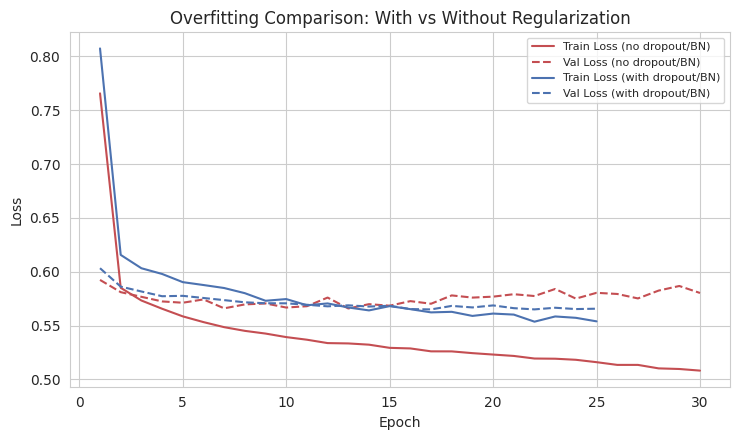

In [14]:
ep_range_ablation = range(1, len(simple_history["train_loss"]) + 1)
plt.figure(figsize=(7.5,4.5))
plt.plot(ep_range_ablation, simple_history["train_loss"], label="Train Loss (no dropout/BN)", color="#C44E52")
plt.plot(ep_range_ablation, simple_history["val_loss"], label="Val Loss (no dropout/BN)", color="#C44E52", linestyle="--")
plt.plot(epochs_range, history["train_loss"], label="Train Loss (with dropout/BN)", color="#4C72B0")
plt.plot(epochs_range, history["val_loss"], label="Val Loss (with dropout/BN)", color="#4C72B0", linestyle="--")
plt.title("Overfitting Comparison: With vs Without Regularization")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig("outputs/05_overfitting_comparison.png", dpi=150); plt.show()

## 9. Architecture diagram

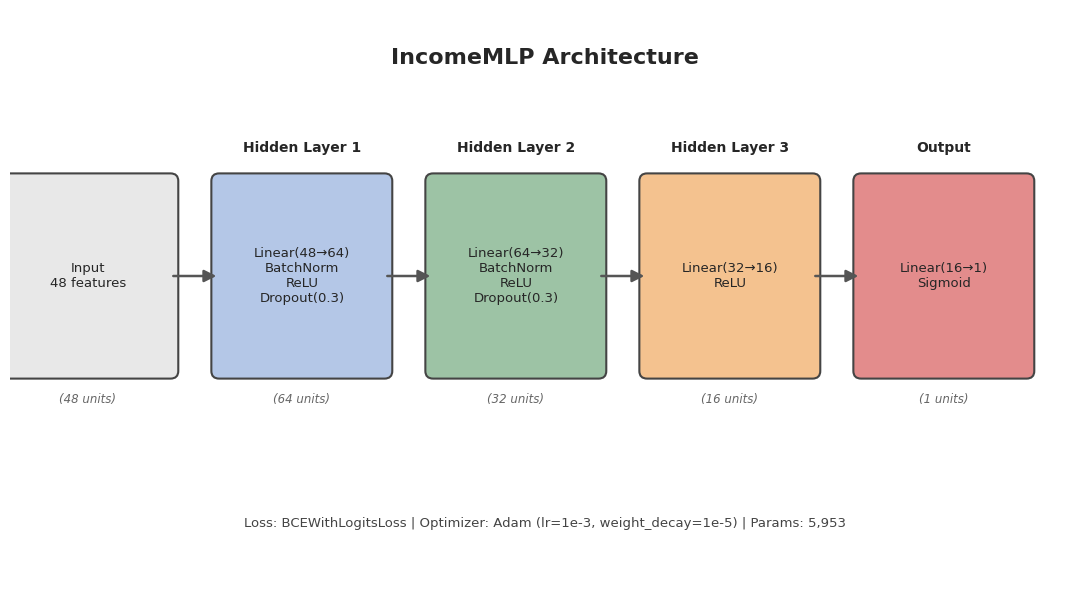

In [15]:
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(11, 6))
ax.set_xlim(0, 11); ax.set_ylim(0, 6); ax.axis("off")

layers = [
    {"name": "Input\n48 features", "x": 0.8, "color": "#E8E8E8", "n": 48, "detail": ""},
    {"name": "Linear(48\u219264)\nBatchNorm\nReLU\nDropout(0.3)", "x": 3.0, "color": "#B4C7E7", "n": 64, "detail": "Hidden Layer 1"},
    {"name": "Linear(64\u219232)\nBatchNorm\nReLU\nDropout(0.3)", "x": 5.2, "color": "#9DC3A5", "n": 32, "detail": "Hidden Layer 2"},
    {"name": "Linear(32\u219216)\nReLU", "x": 7.4, "color": "#F4C28F", "n": 16, "detail": "Hidden Layer 3"},
    {"name": "Linear(16\u21921)\nSigmoid", "x": 9.6, "color": "#E38C8C", "n": 1, "detail": "Output"},
]
box_w, box_h = 1.7, 2.0
y_center = 3.2
for layer in layers:
    box = FancyBboxPatch((layer["x"]-box_w/2, y_center-box_h/2), box_w, box_h,
                          boxstyle="round,pad=0.08,rounding_size=0.08",
                          linewidth=1.5, edgecolor="#444444", facecolor=layer["color"])
    ax.add_patch(box)
    ax.text(layer["x"], y_center, layer["name"], ha="center", va="center", fontsize=9.5)
    if layer["detail"]:
        ax.text(layer["x"], y_center+box_h/2+0.35, layer["detail"], ha="center", va="center", fontsize=10, fontweight="bold")
    ax.text(layer["x"], y_center-box_h/2-0.3, f"({layer['n']} units)", ha="center", va="center", fontsize=8.5, style="italic", color="#666666")
for i in range(len(layers)-1):
    x_start = layers[i]["x"] + box_w/2
    x_end = layers[i+1]["x"] - box_w/2
    arrow = FancyArrowPatch((x_start, y_center), (x_end, y_center), arrowstyle="-|>", mutation_scale=18, linewidth=1.8, color="#555555")
    ax.add_patch(arrow)
ax.text(5.5, 5.5, "IncomeMLP Architecture", ha="center", va="center", fontsize=16, fontweight="bold")
ax.text(5.5, 0.6, "Loss: BCEWithLogitsLoss | Optimizer: Adam (lr=1e-3, weight_decay=1e-5) | Params: 5,953",
        ha="center", va="center", fontsize=9.5, color="#444444")
plt.tight_layout(); plt.savefig("outputs/00_architecture_diagram.png", dpi=150, bbox_inches="tight"); plt.show()